# Random forest: do its assumptions hold, and if so, how accurate is it?

**Goal:** give every booking a chance (0 to 1) of cancelling, then judge those chances the way the client does (`contract.py`).

A random forest grows many decision trees, each on a random sample of the bookings and looking at a random subset of the clues at every question, then averages their chances. Like a tree it needs no straight-line or scaling assumptions; its checklist is about *whether the trees are good enough and different enough for the average to help*.

**What this notebook does, in order**

1. **Set up** and load the bookings, split by time into *train* (the model learns), *choose* (we pick settings and the buffer) and *proof* (the final exam).
2. **Check the assumptions** of random forest on the train period.
3. **Gate.** If every *must-pass* assumption holds, we train. If one fails, the notebook stops and says which.
4. **Train** on train only.
5. **Accuracy**: ordinary classification scores on the choose period.
6. **Accuracy by the contract**: turn the chances into *k* (extra rooms to sell) and score euros, empty rooms, walked guests and walks per 1,000, next to the client's flat rule.
7. **Proof** (the final exam, off by default).

This notebook replaces the random forest part of `src/all_models.py`. The *k* step in section 6 is the same rule as in `06_k_calculator.ipynb`.

## 1. Set up

In [26]:
import importlib.util
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_colwidth", 130)
pd.set_option("display.width", 200)

# --- where is everything? (works whether Jupyter starts in notebooks/ or in the project root) ---
HERE = Path.cwd().resolve()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "notes" / "features_simple.py").exists())
NOTES, SRC = ROOT / "notes", ROOT / "src"
for folder in (NOTES, SRC):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import data               # the starter's data.py: reads hotels.csv (and downloads it if it is missing)
import features_simple    # our cleaning + the Bin 1 clue columns (known on the day of booking)


def load_contract():
    """Load the client's scoring file. We use it exactly as it is and never edit it."""
    for folder in (NOTES, SRC, SRC / "__pycache__"):
        path = folder / "contract.py"
        if path.exists():
            spec = importlib.util.spec_from_file_location("contract", path)
            module = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(module)
            print("scoring file loaded from:", path.relative_to(ROOT))
            return module
    raise FileNotFoundError("contract.py was not found in notes/ or src/")


contract = load_contract()

# --- chart look: one blue line, one orange highlight, quiet grid, dark text ---
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10,
})

scoring file loaded from: src/contract.py


Three switches control the run:

| Switch | Default | Meaning |
|---|---|---|
| `TUNE` | `False` | `True` runs the two-stage search on **train only** (slower), shows every trial, and saves the best setting to `models/hyperparams.json`. `False` shows the results saved by the last run. |
| `RUN_PROOF` | `False` | The proof period is the final exam. Keep it `False` while experimenting. |
| `FORCE_TRAIN` | `False` | `True` trains even if a *must-pass* assumption fails. Not recommended. |

In [27]:
TUNE = True          # True  = run the tuning searches on TRAIN and save the best (slower). False = show the results saved by the last run
RUN_PROOF = False     # the proof period is the FINAL exam: leave this False until everything is decided
FORCE_TRAIN = False   # True  = train even if a MUST-PASS assumption fails (not recommended)


# Starting settings of the forest (used by the assumption checks and by training)
N_TREES = 200          # how many trees are averaged
MAX_DEPTH = 12         # at most 12 questions in a row
MIN_LEAF = 10          # every leaf must hold at least 10 bookings

## 2. Load the bookings and split them by time

In [28]:
raw = data.read_raw()                                     # every booking, exactly as exported
bookings = features_simple.clean_bookings(raw)            # the documented cleaning choices
train, choose, proof = contract.split_periods(bookings)   # split by arrival date, as the contract says
train, choose, proof = [features_simple.add_features(part) for part in (train, choose, proof)]

FEATURES = features_simple.bin1_features                  # the clues known on the day of booking
NUMERIC = features_simple.bin1_numeric_cols
CATEGORICAL = features_simple.bin1_categorical_cols

print(f"bookings: train {len(train):,} | choose {len(choose):,} | proof {len(proof):,}")
print("The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.")

bookings: train 49,108 | choose 29,482 | proof 40,619
The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.


## 3. Do the assumptions of a random forest hold?

We test them on the **train period only**. Each check is either **must pass** (FAIL stops the notebook) or **advisory** (WARN: noted, we still train).

**What a forest does *not* need**: no scaling, no straight-line relationships, no normal distributions. Correlated clues do not break it either (they only share the credit in the importance chart).

| # | Assumption | Why it matters here | How it is tested | Type |
|---|---|---|---|---|
| A1 | The outcome is yes/no | We grow classification trees | `is_canceled` holds only 0 and 1 | must pass |
| A2 | No leakage | A clue only known after the stay gives the answer away | no clue comes from Bin 2 or Bin 3 | must pass |
| A3 | No gaps | The pipeline has no imputer | count empty cells | must pass |
| A4 | Scoring columns present | `contract.nightly_table` needs them | check the names | must pass |
| A5 | Periods follow each other in time | Train before choose before proof | compare dates | must pass |
| A6 | Neither outcome is rare | With a rare outcome, accuracy is misleading | rarer outcome >= 10% | advisory |
| A7 | The past looks like the future | Trees cannot extrapolate beyond what they saw in train | cancel-rate gap and unseen values | must pass |
| R1 | Each tree is better than guessing | Averaging many useless trees stays useless: the forest needs *weak but real* learners | a single pilot tree must reach AUC >= 0.55 on unseen data | must pass |
| R2 | The trees can differ from each other | The average only helps if the trees make different mistakes: each question sees a random subset of the clues | clues per question (the square root of the encoded columns) is more than 1 and less than all | must pass |
| R3 | Enough of the rarer outcome | Leaves must be able to hold both answers | rarer outcome >= 10 x `MIN_LEAF` | must pass |
| R4 | No constant clue | A clue with one value can never split anything | count distinct values | advisory |
| R5 | No near-duplicate numeric clues | Two clues that say the same thing take turns being picked and split their importance | no pair with correlation >= 0.9 | advisory |
| | Enough trees | Too few trees leave the average noisy | **tested after fitting**: log loss vs number of trees, in section 4 | diagnostic |
| | Independent bookings | The chances of bookings on a night are added as if independent | **tested after fitting**, in section 6 | diagnostic |

In [29]:
CHECKS = []    # one row per assumption


def check(name, passed, evidence, must_pass=True):
    """Record one assumption.
       must_pass=True  -> if it fails the status is FAIL and training is stopped.
       must_pass=False -> if it fails the status is WARN: we note it and still train."""
    status = "PASS" if passed else ("FAIL" if must_pass else "WARN")
    CHECKS.append({"assumption": name, "status": status,
                   "type": "must pass" if must_pass else "advisory", "evidence": evidence})

def make_preparer(scale_numbers):
    """Turn the clue columns into numbers. Everything it learns, it learns from the rows it is fitted on."""
    text_step = OneHotEncoder(handle_unknown="ignore", min_frequency=20)   # rare values are grouped together
    number_step = StandardScaler() if scale_numbers else "passthrough"
    return ColumnTransformer([
        ("text", text_step, CATEGORICAL),
        ("numbers", number_step, NUMERIC),
    ])

### A. Checks every model needs (data and contract)

In [30]:
y_train = train["is_canceled"]

# A1. the outcome is a yes/no column with both answers present
check("A1  The outcome is yes/no, with no gaps",
      set(y_train.unique()) == {0, 1} and y_train.notna().all(),
      f"values {sorted(int(v) for v in y_train.unique())}; {y_train.mean():.1%} of train bookings cancelled")

# A2. no clue that is only known AFTER the booking (Bin 2 / Bin 3 columns, or the answer itself)
not_known_at_booking = set(features_simple.bin2_features) | set(features_simple.bin3_features) | {"is_canceled"}
leaky = sorted(set(FEATURES) & not_known_at_booking)
check("A2  No clue that is only known after booking (no leakage)", not leaky,
      f"{len(FEATURES)} clues used; leaky ones: {leaky or 'none'}")

# A3. no empty cells (the pipelines below have no imputer)
gaps = int(train[FEATURES].isna().sum().sum() + choose[FEATURES].isna().sum().sum())
check("A3  No missing values in the clues", gaps == 0, f"{gaps} empty cells in train + choose")

# A4. the columns the scoring file needs
missing_columns = [c for c in contract.REQUIRED if c not in train.columns]
check("A4  The scoring file's columns are present", not missing_columns,
      f"needs {contract.REQUIRED}; missing: {missing_columns or 'none'}")

# A5. the periods follow each other in time (dates only; no proof labels are used)
split_ok = (len(train) > 0 and len(choose) > 0
            and train["arrival_date"].max() < pd.Timestamp(contract.TRAIN_END) <= choose["arrival_date"].min()
            and choose["arrival_date"].max() < pd.Timestamp(contract.PROOF_START))
check("A5  Train, choose and proof follow each other in time", split_ok,
      f"train ends {train['arrival_date'].max().date()}; choose {choose['arrival_date'].min().date()} "
      f"to {choose['arrival_date'].max().date()}")

# A6. neither outcome is rare (advisory)
rarer = min(y_train.mean(), 1 - y_train.mean())
check("A6  Both outcomes are common enough (rarer one >= 10%)", rarer >= 0.10,
      f"the rarer outcome is {rarer:.1%} of train", must_pass=False)

# A7. the past looks like the future: we learn on train and use the model on later nights
rate_gap = abs(choose["is_canceled"].mean() - y_train.mean())
unseen = max((~choose[c].isin(train[c].unique())).mean() for c in CATEGORICAL)
check("A7  The choose period looks like train (cancel-rate gap <= 10 points, unseen values <= 10%)",
      rate_gap <= 0.10 and unseen <= 0.10,
      f"cancel rate {y_train.mean():.1%} -> {choose['is_canceled'].mean():.1%}; "
      f"most unseen values in any one column: {unseen:.1%}")

### B. Checks specific to a random forest

In [31]:
# R1. a single tree trained on the OLDER 80% of train must beat guessing on the NEWEST 20%
ordered = train.sort_values("arrival_date")
cut = int(len(ordered) * 0.8)
older, newer = ordered.iloc[:cut], ordered.iloc[cut:]
pilot = Pipeline([("prepare", make_preparer(scale_numbers=False)),
                  ("model", DecisionTreeClassifier(max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF, random_state=0))])
pilot.fit(older[FEATURES], older["is_canceled"])
pilot_auc = roc_auc_score(newer["is_canceled"], pilot.predict_proba(newer[FEATURES])[:, 1])
check("R1  A single tree is better than guessing (pilot AUC >= 0.55 on unseen data)", pilot_auc >= 0.55,
      f"pilot tree AUC on the newest 20% of train = {pilot_auc:.3f} (0.5 = guessing)")

# R2. the trees can differ: each question looks at a random subset of the encoded columns
preparer = make_preparer(scale_numbers=False).fit(train[FEATURES])
n_columns = preparer.transform(train[FEATURES].head(5)).shape[1]
per_question = int(np.sqrt(n_columns))                  # the forest's default for classification ("sqrt")
check("R2  The trees can differ (each question sees a random subset of the clues)", 1 < per_question < n_columns,
      f"each question looks at {per_question} of {n_columns} encoded columns")

# R3. enough of the rarer outcome for leaves to hold both answers
events = int(min(y_train.sum(), (1 - y_train).sum()))
check(f"R3  Enough of the rarer outcome (>= 10 x MIN_LEAF = {10 * MIN_LEAF:,})", events >= 10 * MIN_LEAF,
      f"{events:,} cases of the rarer outcome")

# R4. no constant clue (advisory)
constant = [c for c in FEATURES if train[c].nunique() <= 1]
check("R4  No clue is constant", not constant, f"constant clues: {constant or 'none'}", must_pass=False)

# R5. no near-duplicate numeric clues (advisory)
corr = train[NUMERIC].astype(float).corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
close = pairs[pairs >= 0.9]
check("R5  No near-duplicate numeric clues (no pair with correlation >= 0.9)", close.empty,
      f"strongest pair: {pairs.idxmax()[0]} & {pairs.idxmax()[1]} (|r| = {pairs.max():.2f})", must_pass=False)

### Verdict

All checks are collected into one table. **FAIL** = a must-pass assumption is broken. **WARN** = an advisory one is, and we carry on.

In [32]:
report = pd.DataFrame(CHECKS).set_index("assumption")
display(report)

failed = report.index[report["status"] == "FAIL"].tolist()
warned = report.index[report["status"] == "WARN"].tolist()
ASSUMPTIONS_OK = not failed
TRAIN_MODEL = ASSUMPTIONS_OK or FORCE_TRAIN

print(f"{(report['status'] == 'PASS').sum()} passed | {len(warned)} warning(s) | {len(failed)} failed")
for name in warned:
    print("   WARN:", name.strip())

if not ASSUMPTIONS_OK:
    verdict = "FAILED (trained anyway: FORCE_TRAIN)"
elif warned:
    verdict = f"PASS with {len(warned)} warning(s)"
else:
    verdict = "PASS"

if not TRAIN_MODEL:
    raise RuntimeError("Must-pass assumption(s) failed, so random forest is NOT trained: "
                       + "; ".join(n.strip() for n in failed)
                       + ". Fix the cause, or set FORCE_TRAIN = True to train anyway.")
print("\nVerdict:", "the must-pass assumptions hold -> we train the random forest." if ASSUMPTIONS_OK
      else "FORCE_TRAIN is on -> training even though a must-pass assumption failed.")

,status,type,evidence
assumption,,,
"A1 The outcome is yes/no, with no gaps",PASS,must pass,"values [0, 1]; 35.8% of train bookings cancelled"
A2 No clue that is only known after booking (no leakage),PASS,must pass,16 clues used; leaky ones: none
A3 No missing values in the clues,PASS,must pass,0 empty cells in train + choose
A4 The scoring file's columns are present,PASS,must pass,"needs ['hotel', 'arrival_date', 'is_canceled', 'adr', 'nights']; missing: none"
"A5 Train, choose and proof follow each other in time",PASS,must pass,train ends 2016-06-30; choose 2016-07-01 to 2016-12-31
A6 Both outcomes are common enough (rarer one >= 10%),PASS,advisory,the rarer outcome is 35.8% of train
"A7 The choose period looks like train (cancel-rate gap <= 10 points, unseen values <= 10%)",PASS,must pass,cancel rate 35.8% -> 36.9%; most unseen values in any one column: 1.7%
R1 A single tree is better than guessing (pilot AUC >= 0.55 on unseen data),PASS,must pass,pilot tree AUC on the newest 20% of train = 0.876 (0.5 = guessing)
R2 The trees can differ (each question sees a random subset of the clues),PASS,must pass,each question looks at 15 of 242 encoded columns


12 passed | 0 warning(s) | 0 failed

Verdict: the must-pass assumptions hold -> we train the random forest.


## 4. Tune and train the random forest

Only reached if the gate above passed. This section shows **how the settings were chosen**: what we tune and why, a wide search, a finer search, a plot, the best setting, and a check that tuning really helps. Every search uses **train only**, in folds that go forward in time, so nothing from the choose or proof periods can influence the choice. Text clues are one-hot encoded (rare values grouped, fitted on train only); numeric clues are used as they are.

`TUNE = True` runs the searches (**slow for a forest**: many trees, many candidates, 3 folds each) and saves the result. `TUNE = False` shows the results saved by the last run.

In [33]:
import datetime
import json

import all_models                                   # src/all_models.py: the same trainers backtest.py uses
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate

# ---- how every search in this section is run ----
SEED = 0                                  # fixed seed: the random search (step 2) tries the same candidates every run
N_SPLITS = 3
CV = TimeSeriesSplit(n_splits=N_SPLITS)   # each fold is tested on bookings that come AFTER the ones it learned from
SCORING = {"log_loss": "neg_log_loss", "auc": "roc_auc"}   # log loss decides; AUC is shown for reference
PREFER_SIMPLER = False    # True = among candidates tied with the best, take the simplest (step 5). False = take the lowest log loss

ordered = train.sort_values("arrival_date")               # time order, as TimeSeriesSplit needs
X_tune, y_tune = ordered[FEATURES], ordered["is_canceled"]

SETTINGS = ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]                    # one column per setting in the trials table
NUMERIC_SETTINGS = ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]             # the ones that have a range (edge check and plot)
INT_SETTINGS = ["n_estimators", "max_depth", "min_samples_leaf"]

EVIDENCE = ROOT / "evidence"
TRIALS_FILE = EVIDENCE / "tuning_random_forest_trials.csv"   # every candidate that was tried
SUMMARY_FILE = EVIDENCE / "tuning_random_forest.json"        # how the search was run + the choice


def number_or_text(v):
    """A CSV stores 0.3 and 'sqrt' in the same column as text: turn the numbers back into numbers."""
    try:
        return float(v)
    except (TypeError, ValueError):
        return v


def tidy_trials(df):
    """A CSV turns None into an empty cell: put it back, so a saved table behaves like a fresh one."""
    df = df.copy()
    if "max_depth" in df:
        df["max_depth"] = pd.Series([None if pd.isna(v) else int(v) for v in df["max_depth"]], index=df.index, dtype=object)
    if "max_features" in df:
        df["max_features"] = pd.Series([number_or_text(v) for v in df["max_features"]], index=df.index, dtype=object)
    return df


trials = summary = None
if not TUNE:
    if TRIALS_FILE.exists() and SUMMARY_FILE.exists():
        trials = tidy_trials(pd.read_csv(TRIALS_FILE))
        summary = json.loads(SUMMARY_FILE.read_text())
        print("TUNE = False: showing the results saved by the last tuning run.")
    else:
        print("TUNE = False and nothing is saved yet. Set TUNE = True at the top and run the notebook once.")

### Step 1. What are we tuning, and why these values?

A *hyper-parameter* is a setting we choose before training. The model cannot learn it from the data, so we try values and keep the ones that predict best on bookings it has not seen. The random forest has four that matter here.

In [34]:
TUNED = pd.DataFrame([
    {"setting": "n_estimators",
     "what it controls": "how many trees are averaged. More trees = steadier chances; it does not overfit by itself, it only costs time",
     "range tried": "100, 200, 300, 500 (step 2), then the neighbours of the best (step 3)",
     "why this range": "the tree-count diagnostic after the final model shows where the curve flattens; 500 is a generous top"},
    {"setting": "max_depth",
     "what it controls": "how many yes/no questions in a row each tree may ask. Small = coarse trees (underfits); large or None = trees that memorise bookings (overfits)",
     "range tried": "6, 8, 12, 16, 24, None = no limit (step 2), then the neighbours of the best (step 3)",
     "why this range": "6 is clearly too shallow and None lets each tree grow until its leaves are small, so the best depth cannot be hiding outside it"},
    {"setting": "min_samples_leaf",
     "what it controls": "the smallest number of bookings a leaf may hold. Small = leaves that follow noise; large = every chance is an average over many bookings",
     "range tried": "1, 2, 3, 5, 10, 20, 50 (step 2), then half to double the best (step 3)",
     "why this range": "from single-booking leaves (1) to leaves that are clearly too smooth for a forest, because the averaging over trees already smooths the chances"},
    {"setting": "max_features",
     "what it controls": "the share of clues each split may look at. Fewer = the trees differ more from each other, which helps the average; more = each tree is stronger but the trees look alike",
     "range tried": "sqrt (about 10% of the encoded clues), 0.1, 0.2, 0.3, 0.5 (step 2), then the neighbours of the best (step 3)",
     "why this range": "from the usual forest default and 10% of the clues up to half of all clues"},
]).set_index("setting")
with pd.option_context("display.max_colwidth", None):
    display(TUNED)
print("Not tuned: random_state = 0 (the same forest every run), bootstrap (left on), class weights (not set: the chances must stay honest), "
      "the encoding (fixed in features.py).")

,what it controls,range tried,why this range
setting,,,
n_estimators,"how many trees are averaged. More trees = steadier chances; it does not overfit by itself, it only costs time","100, 200, 300, 500 (step 2), then the neighbours of the best (step 3)",the tree-count diagnostic after the final model shows where the curve flattens; 500 is a generous top
max_depth,how many yes/no questions in a row each tree may ask. Small = coarse trees (underfits); large or None = trees that memorise bookings (overfits),"6, 8, 12, 16, 24, None = no limit (step 2), then the neighbours of the best (step 3)","6 is clearly too shallow and None lets each tree grow until its leaves are small, so the best depth cannot be hiding outside it"
min_samples_leaf,the smallest number of bookings a leaf may hold. Small = leaves that follow noise; large = every chance is an average over many bookings,"1, 2, 3, 5, 10, 20, 50 (step 2), then half to double the best (step 3)","from single-booking leaves (1) to leaves that are clearly too smooth for a forest, because the averaging over trees already smooths the chances"
max_features,"the share of clues each split may look at. Fewer = the trees differ more from each other, which helps the average; more = each tree is stronger but the trees look alike","sqrt (about 10% of the encoded clues), 0.1, 0.2, 0.3, 0.5 (step 2), then the neighbours of the best (step 3)",from the usual forest default and 10% of the clues up to half of all clues


Not tuned: random_state = 0 (the same forest every run), bootstrap (left on), class weights (not set: the chances must stay honest), the encoding (fixed in features.py).


### Step 2. Wide search: try many combinations

The four settings together make 4 x 6 x 7 x 5 = 840 combinations. A forest is slow to train, so a **random search** tries 30 of them (the same 30 every run, because the seed is fixed). Every candidate is scored on the same three forward-in-time folds. The table lists every candidate, best first. **`log loss`** decides (lower is better), because the safety buffer is built from the *sum* of the chances, so the chances must be honest. `log loss std` is how much the score moved between folds, and `AUC` is shown for reference. The **edge check** below the table says whether the best value sits at the end of a range, which would mean the range is too narrow. A first pass can lower `N_ITER` to save time.

In [35]:
def base_model():
    """The model with the defaults from all_models.py. A search changes only the settings it names."""
    return Pipeline([
        ("prepare", make_preparer(scale_numbers=False)),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=10,
                                         n_jobs=1, random_state=0)),   # = the defaults in all_models.py (n_jobs=1: the search runs the folds in parallel)
    ])


def run_search(search):
    """Fit a search on the time-ordered folds. Returns one row per candidate."""
    search.fit(X_tune, y_tune)
    r = pd.DataFrame(search.cv_results_)
    out = pd.DataFrame(index=r.index)
    for s in SETTINGS:
        values = [None if v is None or pd.isna(v) else (int(v) if s in INT_SETTINGS else v) for v in r[f"param_model__{s}"]]
        out[s] = pd.Series(values, index=r.index, dtype=object)       # object, so a None stays a None
    out["log loss"] = -r["mean_test_log_loss"]
    out["log loss std"] = r["std_test_log_loss"]
    out["AUC"] = r["mean_test_auc"]
    out["fit seconds"] = r["mean_fit_time"]
    for k in range(N_SPLITS):                               # the score of every single fold, kept as evidence
        out[f"fold {k + 1}"] = -r[f"split{k}_test_log_loss"]
    return out


# how to put the values of a setting in order, from the lowest to the highest (None = no limit = the highest)
ORDER = {
    "max_depth": lambda v: float("inf") if v is None else v,
    "min_samples_leaf": lambda v: v,
    "n_estimators": lambda v: v,
    "max_features": lambda v: -1 if v == "sqrt" else v,
}


def edge_check(best_row, space):
    """Is the best value at the lowest or highest end of what was searched? Then the range may be too narrow."""
    at_edge = []
    for s in NUMERIC_SETTINGS:
        values = sorted(space[s], key=ORDER[s])
        v = best_row[s]
        if len(values) > 1 and v == values[0]:
            at_edge.append(f"{s} = {v} (the lowest value tried)")
        elif len(values) > 1 and v == values[-1]:
            if v is None:
                print(f"   note: {s} = None means no limit, so it cannot be widened any further.")
            else:
                at_edge.append(f"{s} = {v} (the highest value tried)")
    return at_edge


STAGE1_SPACE = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [6, 8, 12, 16, 24, None],
    "min_samples_leaf": [1, 2, 3, 5, 10, 20, 50],
    "max_features": ["sqrt", 0.1, 0.2, 0.3, 0.5],
}
N_ITER = 30

if TUNE:
    stage1 = run_search(RandomizedSearchCV(
        base_model(), {f"model__{k}": v for k, v in STAGE1_SPACE.items()}, n_iter=N_ITER,
        scoring=SCORING, cv=CV, refit=False, random_state=SEED, n_jobs=-1))
    stage1.insert(0, "stage", 1)
    trials = stage1

if trials is not None:
    shown = trials[trials["stage"] == 1].sort_values("log loss").reset_index(drop=True)
    display(shown.round(4))
    print(f"{len(shown)} of the {4 * 6 * 7 * 5} possible combinations were tried.")
    best_text = ", ".join(f"{s} = {shown.loc[0, s]}" for s in SETTINGS)
    print(f"Best of the wide search: {best_text}")
    stage1_space = STAGE1_SPACE if TUNE else summary["stage 1 (wide) space"]
    edges = edge_check(shown.loc[0], stage1_space)
    if edges:
        print("-> the best value is at the edge of the range for: " + "; ".join(edges) + ". Widen that range and run again.")
    else:
        print("-> the best values are inside the ranges, so the wide search was wide enough.")

,stage,n_estimators,max_depth,min_samples_leaf,max_features,log loss,log loss std,AUC,fit seconds,fold 1,fold 2,fold 3
0,1,500,16,3,0.2,0.3603,0.0621,0.8973,52.3054,0.2801,0.4312,0.3698
1,1,500,12,3,0.3,0.3616,0.0640,0.8977,71.9673,0.2797,0.4360,0.3690
2,1,500,8,2,0.3,0.3646,0.0712,0.8914,43.5611,0.2719,0.4450,0.3769
3,1,500,16,20,0.3,0.3664,0.0635,0.8948,60.3542,0.2868,0.4421,0.3704
4,1,100,16,2,sqrt,0.3669,0.0610,0.8935,5.1071,0.2847,0.4307,0.3853
5,1,300,24,50,0.2,0.3670,0.0603,0.8898,28.5338,0.2895,0.4366,0.3749
6,1,100,24,50,0.3,0.3682,0.0633,0.8914,13.8101,0.2883,0.4430,0.3733
7,1,100,None,50,0.3,0.3682,0.0633,0.8914,10.0364,0.2883,0.4430,0.3733
8,1,500,8,50,0.3,0.3692,0.0658,0.8895,27.3675,0.2845,0.4450,0.3783
9,1,100,8,20,0.5,0.3698,0.0636,0.8939,13.8632,0.2877,0.4426,0.3792


30 of the 840 possible combinations were tried.
Best of the wide search: n_estimators = 500, max_depth = 16, min_samples_leaf = 3, max_features = 0.2
-> the best value is at the edge of the range for: n_estimators = 500 (the highest value tried). Widen that range and run again.


### Step 3. Finer search around the best region

Now zoom in with a **grid search**: for every setting, the (at most three) values next to the stage 1 winner, so the grid stays small enough for a forest. Every combination in that grid is tried.

In [36]:
MAX_FEATURES_LADDER = ["sqrt", 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]      # a finer ladder than the wide search used
TREES_LADDER = [100, 200, 300, 500]


def make_stage2_space(best):
    """Values next to the stage 1 winner, for every setting (at most 3 each, so the grid stays small)."""
    def around(value, ladder):
        i = ladder.index(value)
        return ladder[max(0, i - 1): i + 2]

    depth, leaf = best["max_depth"], int(best["min_samples_leaf"])
    return {
        "n_estimators": around(int(best["n_estimators"]), TREES_LADDER),
        "max_depth": [24, 32, None] if depth is None else sorted({max(2, int(depth) - 2), int(depth), int(depth) + 2}),
        "min_samples_leaf": sorted({max(1, round(leaf * f)) for f in (0.5, 1, 2)} | {1}),
        "max_features": around(best["max_features"], MAX_FEATURES_LADDER),
    }

if TUNE:
    best_of_stage1 = trials[trials["stage"] == 1].sort_values("log loss").iloc[0]
    STAGE2_SPACE = make_stage2_space(best_of_stage1)
    stage2 = run_search(GridSearchCV(
        base_model(), {f"model__{k}": v for k, v in STAGE2_SPACE.items()},
        scoring=SCORING, cv=CV, refit=False, n_jobs=-1))
    stage2.insert(0, "stage", 2)
    trials = pd.concat([trials, stage2], ignore_index=True)
elif summary is not None:
    STAGE2_SPACE = summary["stage 2 (fine) space"]

if trials is not None:
    shown = trials[trials["stage"] == 2].sort_values("log loss").reset_index(drop=True)
    display(shown.round(4))
    print(f"{len(shown)} combinations tried in the fine search.")
    best_text = ", ".join(f"{s} = {shown.loc[0, s]}" for s in SETTINGS)
    print(f"Best of the fine search: {best_text}")
    edges = edge_check(shown.loc[0], STAGE2_SPACE)
    if edges:
        print("-> the best value is at the edge of the zoomed range for: " + "; ".join(edges)
              + ". The score is still moving, so widen it and run again.")
    else:
        print("-> the best values are inside the zoomed ranges.")

,stage,n_estimators,max_depth,min_samples_leaf,max_features,log loss,log loss std,AUC,fit seconds,fold 1,fold 2,fold 3
0,2,300,14,2,0.2,0.3546,0.0633,0.8987,19.7478,0.2714,0.4249,0.3676
1,2,500,14,2,0.2,0.3548,0.0646,0.8989,39.5976,0.2704,0.4272,0.3668
2,2,300,18,3,0.15,0.3550,0.0635,0.8987,21.4218,0.2722,0.4266,0.3663
3,2,300,16,2,0.15,0.3554,0.0642,0.8983,23.8757,0.2713,0.4269,0.3681
4,2,300,14,2,0.15,0.3555,0.0649,0.8972,21.4709,0.2701,0.4273,0.3690
...,...,...,...,...,...,...,...,...,...,...,...,...
67,2,300,16,1,0.3,0.4034,0.0431,0.8958,36.5125,0.3681,0.4642,0.3780
68,2,500,18,1,0.3,0.4039,0.0571,0.8959,62.0429,0.3436,0.4807,0.3874
69,2,300,18,3,0.3,0.4101,0.0406,0.8959,32.1254,0.3843,0.4675,0.3786
70,2,300,18,1,0.3,0.4136,0.0534,0.8961,40.0245,0.3642,0.4878,0.3889


72 combinations tried in the fine search.
Best of the fine search: n_estimators = 300, max_depth = 14, min_samples_leaf = 2, max_features = 0.2
-> the best value is at the edge of the zoomed range for: n_estimators = 300 (the lowest value tried); max_depth = 14 (the lowest value tried). The score is still moving, so widen it and run again.


### Step 4. Where does the model underfit and overfit?

One panel per setting, showing the best score reached at each value. For `max_depth`, the left of the curve underfits and the right overfits; for `min_samples_leaf` it is the other way round. For `n_estimators` the curve should flatten: past that point more trees only cost time. The best value sits where the curve is lowest. The bars show how much the score moved between the three folds, so two values whose bars overlap are not really different.

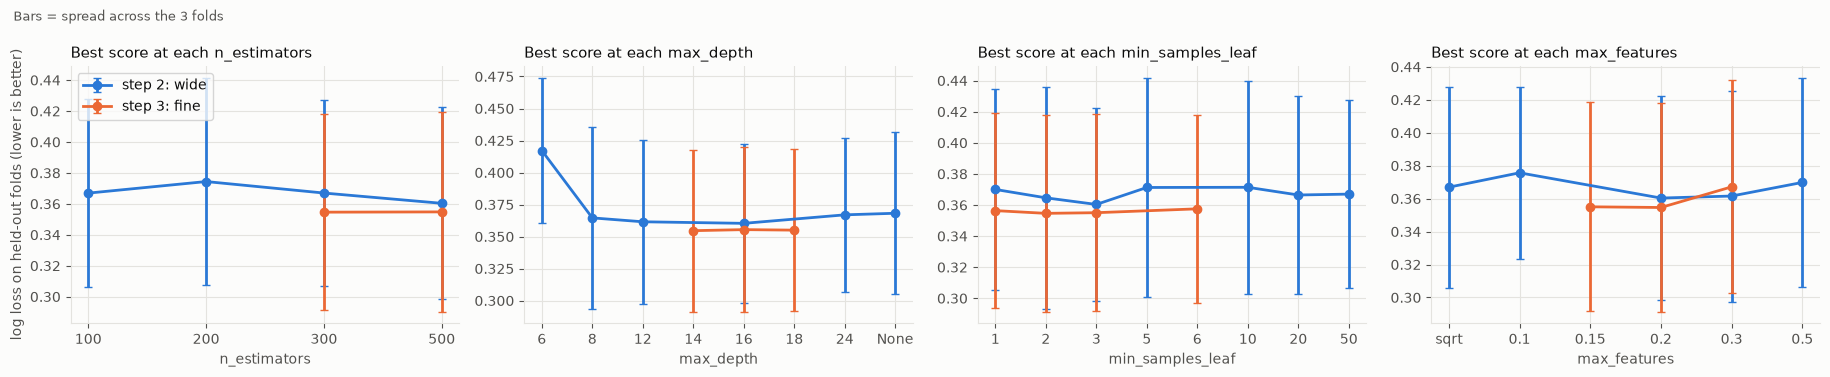

In [37]:
if trials is not None:
    n_panels = len(NUMERIC_SETTINGS)
    fig, axes = plt.subplots(1, n_panels, figsize=(4.6 * n_panels, 3.8), squeeze=False)
    for ax, s in zip(axes[0], NUMERIC_SETTINGS):
        values = sorted(trials[s].unique(), key=ORDER[s])
        position = {v: i for i, v in enumerate(values)}
        for stage, colour, label in ((1, BLUE, "step 2: wide"), (2, ORANGE, "step 3: fine")):
            part = trials[trials["stage"] == stage]
            points = []
            for v in values:                                  # the best score reached at each value of this setting
                rows = part[[x == v for x in part[s]]]
                if len(rows):
                    row = rows.loc[rows["log loss"].idxmin()]
                    points.append((position[v], row["log loss"], row["log loss std"]))
            if points:
                x, y, e = zip(*points)
                ax.errorbar(x, y, yerr=e, marker="o", color=colour, label=label, capsize=3)
        ax.set_xticks(range(len(values)))
        ax.set_xticklabels(["None" if v is None else str(v) for v in values], rotation=45 if len(values) > 8 else 0)
        ax.set_xlabel(s)
        ax.set_title(f"Best score at each {s}")
    axes[0][0].set_ylabel("log loss on held-out folds (lower is better)")
    axes[0][0].legend()
    fig.suptitle("Bars = spread across the 3 folds", x=0.01, ha="left", fontsize=9, color=MUTED)
    fig.tight_layout()
    plt.show()

### Step 5. The best setting

**Rule:** take the lowest log loss. Another candidate counts as *tied* with it if its average gap to the best, measured **fold by fold**, is smaller than one standard error of that gap. (Comparing fold by fold removes the noise all candidates share, such as one fold simply being a harder period.) Among the tied candidates we choose the simplest forest: the smallest `max_depth`, then the largest `min_samples_leaf`, then the fewest trees. A simpler model generalises better and its chances tend to be better calibrated. Set `PREFER_SIMPLER = False` at the top of this section to take the lowest log loss instead. With only 3 folds the standard error is large, so many candidates count as tied: check the chosen row against the plot in step 4.

In [38]:
if trials is not None:
    fold_cols = [f"fold {k + 1}" for k in range(N_SPLITS)]
    pool = trials.drop_duplicates(SETTINGS).copy()          # a combination tried in both searches counts once
    best = pool.sort_values("log loss").iloc[0]
    gap = pool[fold_cols].sub(best[fold_cols], axis=1)      # this candidate minus the best, fold by fold
    pool["gap to best"] = gap.mean(axis=1)
    pool["one std error"] = gap.std(axis=1, ddof=1) / np.sqrt(N_SPLITS)
    tied = pool[pool["gap to best"] <= pool["one std error"]].copy()
    tied["_depth"] = [float("inf") if v is None else v for v in tied["max_depth"]]       # None = no limit = deepest
    tied = tied.sort_values(["_depth", "min_samples_leaf", "n_estimators"], ascending=[True, False, True]).drop(columns="_depth")
    chosen = tied.iloc[0] if PREFER_SIMPLER else best       # tied.iloc[0] = the simplest of the tied candidates
    chosen_params = {f"model__{s}": chosen[s] for s in SETTINGS}   # exactly what all_models.set_params receives


    def describe(row):
        return ", ".join(f"{s} = {row[s]}" for s in SETTINGS)


    print(f"BEST SETTING:  {describe(chosen)}")
    print(f"  lowest log loss overall: {describe(best)} (log loss {best['log loss']:.4f})")
    if PREFER_SIMPLER:
        print(f"  {len(tied)} candidate(s) are tied with it (gap within one standard error); the simplest of them is chosen")
    else:
        print("  PREFER_SIMPLER = False: the lowest log loss is taken as it is")
    print(f"  chosen: log loss {chosen['log loss']:.4f}, AUC {chosen['AUC']:.4f}")
    display(tied[SETTINGS + ["log loss", "AUC", "gap to best", "one std error"]].round(4).reset_index(drop=True))

    if TUNE:
        summary = {
            "model": "random forest",
            "tuned_on": (f"train period only ({train['arrival_date'].min().date()} to {train['arrival_date'].max().date()}), "
                         f"{N_SPLITS} forward-in-time folds (TimeSeriesSplit)"),
            "scoring": "mean log loss over the folds (lower is better); AUC recorded for reference",
            "seed": SEED,
            "settings_searched": [f"model__{s}" for s in SETTINGS],
            "stage 1 (wide) search": f"RandomizedSearchCV, n_iter = {N_ITER}",
            "stage 1 (wide) space": STAGE1_SPACE,
            "stage 2 (fine) search": "GridSearchCV over the neighbours of the stage 1 winner",
            "stage 2 (fine) space": STAGE2_SPACE,
            "n_trials": int(len(pool)),
            "prefer_simpler": PREFER_SIMPLER,
            "rule": ("lowest log loss; candidates whose fold-by-fold gap to it is within one standard error count as tied, "
                     "and the simplest of them (smallest max_depth, then largest min_samples_leaf, then fewest trees) is chosen" if PREFER_SIMPLER else "lowest log loss"),
            "lowest_log_loss_setting": {f"model__{s}": best[s] for s in SETTINGS},
            "chosen": chosen_params,
            "chosen_log_loss": float(chosen["log loss"]),
        }

BEST SETTING:  n_estimators = 300, max_depth = 14, min_samples_leaf = 2, max_features = 0.2
  lowest log loss overall: n_estimators = 300, max_depth = 14, min_samples_leaf = 2, max_features = 0.2 (log loss 0.3546)
  PREFER_SIMPLER = False: the lowest log loss is taken as it is
  chosen: log loss 0.3546, AUC 0.8987


,n_estimators,max_depth,min_samples_leaf,max_features,log loss,AUC,gap to best,one std error
0,300,14,3,0.2,0.3563,0.8982,0.00164,0.002228
1,300,14,2,0.15,0.3555,0.8972,0.000846,0.001104
2,300,14,2,0.2,0.3546,0.8987,0.0,0.0
3,500,14,2,0.2,0.3548,0.8989,0.000177,0.001076
4,300,16,3,0.15,0.3556,0.8979,0.000964,0.001004
5,300,18,3,0.15,0.3550,0.8987,0.000418,0.000878


### Step 6. Does tuning help? Tuned vs default

The default settings (the ones in `all_models.py`) and the chosen settings, scored on the same three folds. If the gain is tiny, tuning did not matter much, and that is also a result worth reporting.

In [39]:
DEFAULT_PARAMS = {"model__n_estimators": 200, "model__max_depth": 12, "model__min_samples_leaf": 10, "model__max_features": "sqrt"}   # the defaults in all_models.py


def fold_scores(params):
    r = cross_validate(base_model().set_params(**params), X_tune, y_tune, cv=CV, scoring=SCORING, n_jobs=-1)
    return pd.DataFrame({"log loss": -r["test_log_loss"], "AUC": r["test_auc"]}, index=range(1, N_SPLITS + 1))


def params_text(params):
    return ", ".join(f"{k.replace('model__', '')} = {v}" for k, v in params.items())


if trials is not None:
    if TUNE:
        default, tuned = fold_scores(DEFAULT_PARAMS), fold_scores(chosen_params)
        summary["vs_default"] = {
            "default settings": DEFAULT_PARAMS, "chosen settings": chosen_params,
            "default log loss": float(default["log loss"].mean()), "tuned log loss": float(tuned["log loss"].mean()),
            "default AUC": float(default["AUC"].mean()), "tuned AUC": float(tuned["AUC"].mean()),
            "default log loss by fold": [float(x) for x in default["log loss"]],
            "tuned log loss by fold": [float(x) for x in tuned["log loss"]],
        }
    v = summary["vs_default"]
    compare = pd.DataFrame({
        "default": [v["default log loss"], v["default AUC"]],
        "tuned": [v["tuned log loss"], v["tuned AUC"]],
    }, index=["mean log loss (lower is better)", "mean AUC (higher is better)"])
    compare["difference"] = compare["tuned"] - compare["default"]
    print("default:", params_text(v["default settings"]))
    print("tuned:  ", params_text(v["chosen settings"]))
    display(compare.round(4))

    gain = v["default log loss"] - v["tuned log loss"]
    if gain > 0.002:
        print(f"-> tuning helped: the log loss fell by {gain:.4f}.")
    elif gain >= -0.002:
        print(f"-> the difference is tiny ({gain:+.4f} log loss): the default was already close. Report that tuning changed little.")
    else:
        print(f"-> the chosen setting is worse than the default by {-gain:.4f} log loss on these folds. Look at the plot in step 4 before using it.")

default: n_estimators = 200, max_depth = 12, min_samples_leaf = 10, max_features = sqrt
tuned:   n_estimators = 300, max_depth = 14, min_samples_leaf = 2, max_features = 0.2


,default,tuned,difference
mean log loss (lower is better),0.3876,0.3546,-0.033
mean AUC (higher is better),0.8857,0.8987,0.013


-> tuning helped: the log loss fell by 0.0330.


### Step 7. Save the choice

With `TUNE = True` this saves three things: the chosen settings in `models/hyperparams.json` (what `backtest.py` trains with), and the full table of trials plus the search summary in `evidence/` (the proof of how the settings were chosen). It also prints a row for `docs/DECISIONS.md`: check the wording, then paste it into the team decisions table.

In [40]:
if TUNE and summary is not None:
    EVIDENCE.mkdir(exist_ok=True)
    trials.to_csv(TRIALS_FILE, index=False)
    SUMMARY_FILE.write_text(json.dumps(summary, indent=2))
    all_models.save_hyperparams("random forest", summary["chosen"])
    print("saved: models/hyperparams.json  (the settings backtest.py trains with)")
    print("saved:", TRIALS_FILE.relative_to(ROOT), "and", SUMMARY_FILE.relative_to(ROOT))

if summary is not None:
    v = summary["vs_default"]
    print("\nRow for docs/DECISIONS.md (team decisions table). Check the wording before you paste it:\n")
    print(f"| {datetime.date.today()} | notebooks/05_model_random_forest.ipynb | Random forest: {params_text(v['chosen settings'])}. "
          f"Chosen from {summary['n_trials']} trials (n_estimators 100 to 500, max_depth 6 to None, min_samples_leaf 1 to 50, max_features sqrt to 0.5) on train only, {N_SPLITS} forward-in-time folds, scored by log loss. "
          f"Rule: {summary['rule']}. "
          f"Cross-validated log loss {v['tuned log loss']:.4f} against {v['default log loss']:.4f} for the defaults ({params_text(v['default settings'])}). | | | |")

saved: models/hyperparams.json  (the settings backtest.py trains with)
saved: evidence/tuning_random_forest_trials.csv and evidence/tuning_random_forest.json

Row for docs/DECISIONS.md (team decisions table). Check the wording before you paste it:

| 2026-11-17 | notebooks/05_model_random_forest.ipynb | Random forest: n_estimators = 300, max_depth = 14, min_samples_leaf = 2, max_features = 0.2. Chosen from 101 trials (n_estimators 100 to 500, max_depth 6 to None, min_samples_leaf 1 to 50, max_features sqrt to 0.5) on train only, 3 forward-in-time folds, scored by log loss. Rule: lowest log loss. Cross-validated log loss 0.3546 against 0.3876 for the defaults (n_estimators = 200, max_depth = 12, min_samples_leaf = 10, max_features = sqrt). | | | |


### Train the final model

The model used in the rest of this notebook is trained by `all_models.train_forest`, the same function `backtest.py` calls, with the saved settings. So the notebook and `backtest.py` always train the same model.

In [41]:
model = all_models.train_forest(train)                      # learn from train only, with the saved settings
print("settings used:", all_models.load_hyperparams("random forest") or "none saved yet, so the defaults")
print("trained on", f"{len(train):,}", "train bookings")
forest = model.named_steps["model"]
print(f"{len(forest.estimators_)} trees")

settings used: {'model__n_estimators': 300, 'model__max_depth': 14, 'model__min_samples_leaf': 2, 'model__max_features': 0.2}
trained on 49,108 train bookings
300 trees


**Diagnostic: are there enough trees?** We average the first 5, 10, 25 ... trees on the choose period. Once the log loss goes flat, more trees would not help.

In [42]:
X_choose = model.named_steps["prepare"].transform(choose[FEATURES])
per_tree = np.array([tree.predict_proba(X_choose)[:, 1] for tree in forest.estimators_])   # one row per tree
counts = sorted({n for n in (1, 5, 10, 25, 50, 100, 200, 300) if n < len(forest.estimators_)} | {len(forest.estimators_)})
curve = pd.Series({n: log_loss(choose["is_canceled"], per_tree[:n].mean(axis=0)) for n in counts}, name="log loss on choose")
curve.index.name = "number of trees"
display(curve.round(4).to_frame())
change = curve.iloc[-1] - curve.iloc[-2]
print(f"Going from {curve.index[-2]} to {curve.index[-1]} trees changed the log loss by {change:+.4f} (negative = better)")
print("-> the curve has levelled off: enough trees." if abs(change) < 0.002
      else "-> the curve is still moving: more trees may help.")

,log loss on choose
number of trees,
1,1.9043
5,0.4863
10,0.4615
25,0.4620
50,0.4585
100,0.4603
200,0.4584
300,0.4599


Going from 200 to 300 trees changed the log loss by +0.0016 (negative = better)
-> the curve has levelled off: enough trees.


In [43]:
# Which clues does the forest lean on most? (importance of each encoded clue, top 10)
names = model.named_steps["prepare"].get_feature_names_out()
importance = pd.Series(forest.feature_importances_, index=names).sort_values(ascending=False)
display(importance.head(10).round(3).rename("importance").to_frame())

,importance
text__deposit_type_Non Refund,0.182
numbers__previous_cancellations,0.165
text__deposit_type_No Deposit,0.158
text__country_PRT,0.126
numbers__lead_time,0.093
numbers__adr,0.034
text__agent_9,0.025
text__customer_type_Transient,0.017
text__market_segment_Groups,0.015
text__customer_type_Transient-Party,0.013


## 5. Accuracy on the choose period

The model learned from train only, so the choose period is data it has never seen. First the ordinary scores, then (section 6) the scores that matter to the client.

In [44]:
def predict_chances(model, df):
    """A chance of cancelling (0 to 1) for every booking."""
    return model.predict_proba(df[FEATURES])[:, 1]     # column 0 = chance of staying, column 1 = chance of cancelling


def get_scores(df, chances):
    """Ordinary classification scores, using 0.5 as the cut-off."""
    answers = df["is_canceled"]
    guesses = (chances >= 0.5).astype(int)
    true_stays, false_cancels, missed_cancels, true_cancels = confusion_matrix(answers, guesses).ravel()
    return {
        "accuracy": accuracy_score(answers, guesses),             # share of bookings guessed right
        "always_stays": 1 - answers.mean(),                       # accuracy if we just said "nobody cancels"
        "auc": roc_auc_score(answers, chances),                   # 0.5 = guessing, 1.0 = perfect
        "log_loss": log_loss(answers, chances),                   # punishes confident wrong chances
        "precision": precision_score(answers, guesses, zero_division=0),   # of "will cancel" guesses, how many did
        "recall": recall_score(answers, guesses),                 # of the real cancels, how many we caught
        "f1": f1_score(answers, guesses),                         # one number mixing precision and recall
        "true_stays": true_stays, "false_cancels": false_cancels,
        "missed_cancels": missed_cancels, "true_cancels": true_cancels,
    }


def show_scores(scores, chances, df):
    table = pd.Series({
        "accuracy": scores["accuracy"],
        "accuracy of always guessing 'stays' (the bar to beat)": scores["always_stays"],
        "AUC": scores["auc"], "log loss": scores["log_loss"],
        "precision": scores["precision"], "recall": scores["recall"], "f1": scores["f1"],
    }, name="choose period")
    display(table.round(3).to_frame())
    display(pd.DataFrame([[scores["true_stays"], scores["false_cancels"]],
                          [scores["missed_cancels"], scores["true_cancels"]]],
                         index=["really stayed", "really cancelled"],
                         columns=["guessed: stays", "guessed: cancels"]))
    beat = "BEATS" if scores["accuracy"] > scores["always_stays"] else "does NOT beat"
    print(f"Accuracy {scores['accuracy']:.3f} {beat} the always-'stays' guess ({scores['always_stays']:.3f}).")
    expected, actual = chances.sum(), int(df["is_canceled"].sum())
    print(f"Chances add up to {expected:,.0f} cancellations; {actual:,} really happened "
          f"({expected / actual:.0%}). The buffer is built from this sum, so this matters.")


chances_choose = predict_chances(model, choose)
scores = get_scores(choose, chances_choose)
show_scores(scores, chances_choose, choose)

,choose period
accuracy,0.755
accuracy of always guessing 'stays' (the bar to beat),0.631
AUC,0.843
log loss,0.460
precision,0.883
recall,0.389
f1,0.540


,guessed: stays,guessed: cancels
really stayed,18036,562
really cancelled,6655,4229


Accuracy 0.755 BEATS the always-'stays' guess (0.631).
Chances add up to 9,030 cancellations; 10,884 really happened (83%). The buffer is built from this sum, so this matters.


## 6. Accuracy by the contract

The client does not score "was the guess right?". It scores **what the rule costs**, night by night (`docs/EVALUATION_CONTRACT.md`):

1. `contract.nightly_table` adds up the chances of one hotel's bookings on one night: `expected` cancellations and their `spread` (standard deviation).
2. We hold back a safety buffer: **k = floor(expected − z × spread)** extra rooms to sell. `z` is how many standard deviations we hold back (bigger `z` = more careful).
3. `contract.night_cost` compares *k* with what really happened: an empty room costs that night's average stay value, a walked guest costs EUR 300.
4. A rule is acceptable only if it walks **10 or fewer guests per 1,000 arrivals**. We pick the **cheapest `z` that stays inside that limit, on the choose period**.

In [45]:
Z_GRID = [round(i * 0.1, 1) for i in range(0, 41)]   # 0.0 ... 4.0 (a buffer only holds rooms back)
MARGIN_GRID = list(range(0, 61))                       # 0 ... 60 rooms


def calculate_k(nights, buffer, kind="z"):
    """k = how many EXTRA rooms to sell on each night.
       kind="z"      -> k = floor(expected - z x spread). Used for the models.
       kind="margin" -> k = floor(expected) - margin.     Used for the client's flat rule."""
    if kind == "margin":
        k = np.floor(nights["expected"]) - buffer
    else:
        k = np.floor(nights["expected"] - buffer * nights["spread"])
    k = np.clip(k, 0, None)        # k is never below 0
    return k.astype(int)           # whole rooms only


def avg_rooms_held_back(nights, buffer, kind="z"):
    """The buffer expressed in rooms per night, so z and margin can be compared."""
    if kind == "margin":
        return float(buffer)
    return float(buffer * nights["spread"].mean())


def find_best_buffer(nights, kind="z"):
    """Try many buffers and keep the CHEAPEST one that stays inside the walk limit.
       Run this on the CHOOSE period only. Returns the buffer and its score."""
    buffers_to_try = MARGIN_GRID if kind == "margin" else Z_GRID
    best_buffer, best_result = None, None
    for buffer in buffers_to_try:
        result = contract.night_cost(nights, calculate_k(nights, buffer, kind))   # the starter scores it for us
        if result["ceiling_met"]:                                                 # only buffers inside the walk limit count
            if best_result is None or result["cost_eur"] < best_result["cost_eur"]:
                best_buffer, best_result = buffer, result
    if best_result is None:
        raise ValueError("No buffer stayed inside the walk limit. Try a bigger range of buffers.")
    if best_buffer in (buffers_to_try[0], buffers_to_try[-1]):
        print(f"   WARNING: best buffer {best_buffer} is at the edge of the grid; widen the grid.")
    return best_buffer, best_result


def sweep_buffers(nights, kind="z"):
    """The score of EVERY buffer in the grid (for the chart)."""
    grid = MARGIN_GRID if kind == "margin" else Z_GRID
    rows = [{"buffer": b, **contract.night_cost(nights, calculate_k(nights, b, kind))} for b in grid]
    return pd.DataFrame(rows)


def plot_buffer_sweep(sweep, best_buffer, xlabel, title):
    """Left: what each buffer costs. Right: how many guests it walks (the client allows at most 10 per 1,000).
       The grey zone is every buffer that breaks that limit; the orange dot is the cheapest buffer outside it."""
    fig, (ax_cost, ax_walk) = plt.subplots(1, 2, figsize=(11, 3.6))
    within = sweep[sweep["walks_per_1000"] <= contract.WALK_CEILING]
    edge = within["buffer"].min() if len(within) else sweep["buffer"].max()
    best = sweep.loc[sweep["buffer"] == best_buffer].iloc[0]

    ax_cost.plot(sweep["buffer"], sweep["cost_eur"] / 1e6, color=BLUE)
    ax_cost.plot(best_buffer, best["cost_eur"] / 1e6, "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_cost.annotate(f"cheapest safe buffer: {best_buffer}", (best_buffer, best["cost_eur"] / 1e6),
                     xytext=(10, -18), textcoords="offset points", color=MUTED)
    ax_cost.set_ylabel("cost on the choose period (EUR millions)")

    ax_walk.plot(sweep["buffer"], sweep["walks_per_1000"], color=BLUE)
    ax_walk.axhline(contract.WALK_CEILING, color=MUTED, linestyle="--", linewidth=1)
    ax_walk.annotate(f"client limit: {contract.WALK_CEILING:g} per 1,000", (sweep["buffer"].max(), contract.WALK_CEILING),
                     xytext=(0, 4), textcoords="offset points", ha="right", color=MUTED)
    ax_walk.plot(best_buffer, best["walks_per_1000"], "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_walk.set_ylabel("walked guests per 1,000 arrivals")

    for ax in (ax_cost, ax_walk):
        ax.axvspan(sweep["buffer"].min(), edge, color=GRID, alpha=0.6, zorder=0)
        ax.set_xlabel(xlabel)
    ax_cost.set_title(title + ": cost")
    ax_walk.set_title(title + ": walks")
    ax_cost.text(0.02, 0.96, "grey = breaks the walk limit", transform=ax_cost.transAxes, va="top", color=MUTED)
    fig.tight_layout()
    plt.show()

Best buffer on the choose period: z = 0.1 std devs = 0.3 rooms held back per night on average


,random forest on the choose period
cost (EUR),1020168.06
empty rooms,2328
walked guests,181
"walks per 1,000 arrivals",9.73
walk limit met (<= 10),True
nights scored,368
nightly error (rooms),6.33


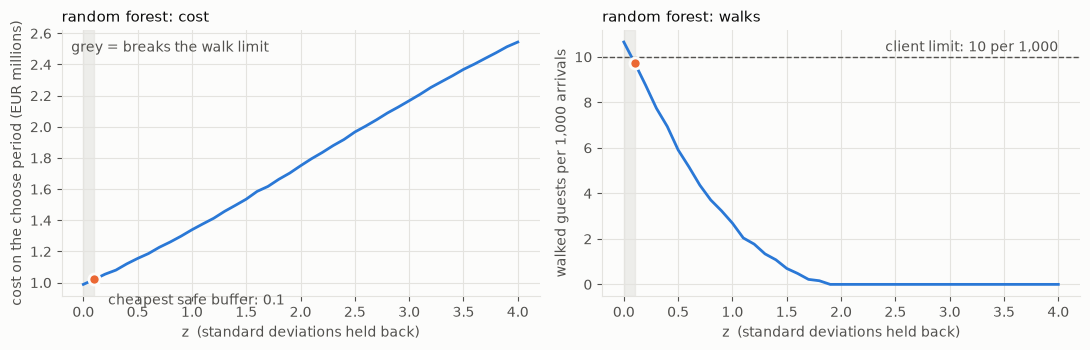

In [46]:
def nightly_error(nights):
    """Average gap, in rooms, between expected and real cancellations per night."""
    return (nights["expected"] - nights["cancelled"]).abs().mean()


nights_choose = contract.nightly_table(choose, chances_choose)      # one row per hotel and night
best_z, best = find_best_buffer(nights_choose)                       # the cheapest z inside the walk limit
rooms_held_back = avg_rooms_held_back(nights_choose, best_z)

print(f"Best buffer on the choose period: z = {best_z} std devs "
      f"= {rooms_held_back:.1f} rooms held back per night on average")
display(pd.Series({
    "cost (EUR)": best["cost_eur"],
    "empty rooms": best["empty_rooms"],
    "walked guests": best["walked_guests"],
    "walks per 1,000 arrivals": best["walks_per_1000"],
    "walk limit met (<= 10)": best["ceiling_met"],
    "nights scored": best["nights"],
    "nightly error (rooms)": round(nightly_error(nights_choose), 2),
}, name="random forest on the choose period").to_frame())

sweep = sweep_buffers(nights_choose)
plot_buffer_sweep(sweep, best_z, "z  (standard deviations held back)", "random forest")

**Reading the chart.** Cost rises with `z` (more empty rooms) while walks fall. The grey zone is every `z` that walks too many guests, so it is not allowed even though it is cheaper. The orange dot is the cheapest `z` just outside it.

### The client's flat rule (the yardstick)

The contract says every saving is a saving **against the client's flat rule**, never against selling nothing extra. The flat rule gives each booking its hotel's average cancellation rate from train, then holds back a fixed number of rooms (its margin, chosen on the choose period under the same walk limit).

In [47]:
# The client's flat rule is only a yardstick (it is not one of our models):
#   chance of cancelling = that hotel's cancellation rate in TRAIN, k = floor(rate x bookings) - margin.
# Every saving is measured against it, never against "sell nothing extra".
hotel_rate = train.groupby("hotel")["is_canceled"].mean()


def flat_rule_nights(df):
    chances = df["hotel"].map(hotel_rate).to_numpy()       # every booking gets its hotel's average rate
    return contract.nightly_table(df, chances)


flat_choose = flat_rule_nights(choose)
flat_margin, flat_best = find_best_buffer(flat_choose, kind="margin")
print(f"Client's flat rule: hotel rates from train {hotel_rate.round(3).to_dict()}")
print(f"Best safety margin on the choose period: {flat_margin} rooms  "
      f"(cost EUR {flat_best['cost_eur']:,.0f}, walks per 1,000 {flat_best['walks_per_1000']})")


comparison = pd.DataFrame([
    {"rule": "client's flat rule", "buffer": f"{flat_margin} rooms",
     "cost EUR": flat_best["cost_eur"], "empty rooms": flat_best["empty_rooms"],
     "walked guests": flat_best["walked_guests"], "walks per 1,000": flat_best["walks_per_1000"],
     "limit met": flat_best["ceiling_met"], "saving vs flat rule EUR": 0.0},
    {"rule": "random forest + z-buffer", "buffer": f"z = {best_z} (~{rooms_held_back:.1f} rooms)",
     "cost EUR": best["cost_eur"], "empty rooms": best["empty_rooms"],
     "walked guests": best["walked_guests"], "walks per 1,000": best["walks_per_1000"],
     "limit met": best["ceiling_met"], "saving vs flat rule EUR": flat_best["cost_eur"] - best["cost_eur"]},
]).set_index("rule")
display(comparison)

Client's flat rule: hotel rates from train {'City Hotel': 0.417, 'Resort Hotel': 0.252}
Best safety margin on the choose period: 16 rooms  (cost EUR 2,416,541, walks per 1,000 9.25)


,buffer,cost EUR,empty rooms,walked guests,"walks per 1,000",limit met,saving vs flat rule EUR
rule,,,,,,,
client's flat rule,16 rooms,2416540.66,5529,172,9.25,True,0.0
random forest + z-buffer,z = 0.1 (~0.3 rooms),1020168.06,2328,181,9.73,True,1396372.6


### Do bookings on the same night cancel independently?

Every one of these models (and the contract's `spread`) assumes **independent bookings**. That cannot be tested before the model exists, so we test it now. If bookings are independent, the real night-to-night gap `cancelled − expected` should have the same variance as the contract's `spread²`, a ratio of about 1.

In [48]:
gap = nights_choose["cancelled"] - nights_choose["expected"]
variance_ratio = gap.var() / (nights_choose["spread"] ** 2).mean()
print(f"real variance of (cancelled - expected) / variance the contract assumes = {variance_ratio:.1f}")
if variance_ratio <= 1.5:
    print("About 1: bookings behave as if independent, so the spread is a fair measure of the risk.")
else:
    print(f"Well above 1: bookings on the same night cancel more together than independence allows, so the "
          f"real swings are about {variance_ratio ** 0.5:.1f}x bigger than `spread` says.\n"
          "The independence assumption is only roughly true. This is not a reason to stop, but it is why "
          "the buffer z is FOUND by search on the choose period instead of being taken from a textbook "
          "value like 1.64.")

real variance of (cancelled - expected) / variance the contract assumes = 8.1
Well above 1: bookings on the same night cancel more together than independence allows, so the real swings are about 2.8x bigger than `spread` says.
The independence assumption is only roughly true. This is not a reason to stop, but it is why the buffer z is FOUND by search on the choose period instead of being taken from a textbook value like 1.64.


## 7. Proof: the final exam (run once, at the very end)

The contract allows **one** look at the proof period (1 January to 31 August 2017). We use the model exactly as trained above and the `z` and margin chosen on the choose period. **Nothing is changed after seeing the result.** If you do change something afterwards, the contract says to report both runs.

Set `RUN_PROOF = True` in the switches cell only when everything else is final.

In [49]:
if not RUN_PROOF:
    print("RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.")
    proof_row = None
else:
    chances_proof = predict_chances(model, proof)
    proof_scores = get_scores(proof, chances_proof)
    nights_proof = contract.nightly_table(proof, chances_proof)
    model_proof = contract.night_cost(nights_proof, calculate_k(nights_proof, best_z))          # the z chosen earlier

    flat_nights_proof = flat_rule_nights(proof)
    flat_proof = contract.night_cost(flat_nights_proof, calculate_k(flat_nights_proof, flat_margin, "margin"))

    proof_row = pd.DataFrame([
        {"rule": "client's flat rule", "accuracy": None, "AUC": None, "cost EUR": flat_proof["cost_eur"],
         "empty rooms": flat_proof["empty_rooms"], "walked guests": flat_proof["walked_guests"],
         "walks per 1,000": flat_proof["walks_per_1000"], "limit met": flat_proof["ceiling_met"],
         "saving vs flat rule EUR": 0.0},
        {"rule": "random forest + z-buffer", "accuracy": proof_scores["accuracy"], "AUC": proof_scores["auc"],
         "cost EUR": model_proof["cost_eur"], "empty rooms": model_proof["empty_rooms"],
         "walked guests": model_proof["walked_guests"], "walks per 1,000": model_proof["walks_per_1000"],
         "limit met": model_proof["ceiling_met"],
         "saving vs flat rule EUR": flat_proof["cost_eur"] - model_proof["cost_eur"]},
    ]).set_index("rule")
    display(proof_row.round(3))

RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.


## 8. One-line summary

In [50]:
summary = pd.Series({
    "model": "random forest",
    "assumptions": verdict,
    "accuracy (choose)": round(scores["accuracy"], 3),
    "always-'stays' accuracy": round(scores["always_stays"], 3),
    "AUC (choose)": round(scores["auc"], 3),
    "z chosen (std devs)": best_z,
    "cost EUR (choose)": best["cost_eur"],
    "walks per 1,000 (choose)": best["walks_per_1000"],
    "walk limit met": best["ceiling_met"],
    "saving vs flat rule EUR (choose)": round(flat_best["cost_eur"] - best["cost_eur"], 2),
    "proof run": "done" if RUN_PROOF else "not run",
}, name="result")
display(summary.to_frame())

,result
model,random forest
assumptions,PASS
accuracy (choose),0.755
always-'stays' accuracy,0.631
AUC (choose),0.843
z chosen (std devs),0.1
cost EUR (choose),1020168.06
"walks per 1,000 (choose)",9.73
walk limit met,True
saving vs flat rule EUR (choose),1396372.6
